# Lab 7: Support Vector Machine on Virat Kohli's Innings

MLPR, Semester 4. Predicts the match format (ODI, T20 or Test) of an innings from the runs scored and the strike rate, using an SVM with a polynomial kernel. A sweep over the polynomial degree shows underfitting and overfitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score

frames = []
for fmt, file in [("ODI", "odi"), ("T20", "t20i"), ("TEST", "test")]:
    d = pd.read_csv(f"data/virat_kohli_{file}_innings_data.csv")
    frames.append(pd.DataFrame({"Runs": pd.to_numeric(d["Runs"], errors="coerce").fillna(0),
                                "SR": pd.to_numeric(d["SR"], errors="coerce").fillna(0),
                                "match_type": fmt}))
data_cricketer = pd.concat(frames, ignore_index=True)
print(data_cricketer["match_type"].value_counts().to_dict())

X, Y = data_cricketer[["Runs", "SR"]], data_cricketer["match_type"]
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=0)

{'ODI': 262, 'TEST': 180, 'T20': 114}


Accuracy: 0.6886, balanced accuracy: 0.6849



              precision    recall  f1-score   support

         ODI       0.72      0.72      0.72        78
         T20       0.67      0.69      0.68        32
        TEST       0.66      0.65      0.65        57

    accuracy                           0.69       167
   macro avg       0.68      0.68      0.68       167
weighted avg       0.69      0.69      0.69       167



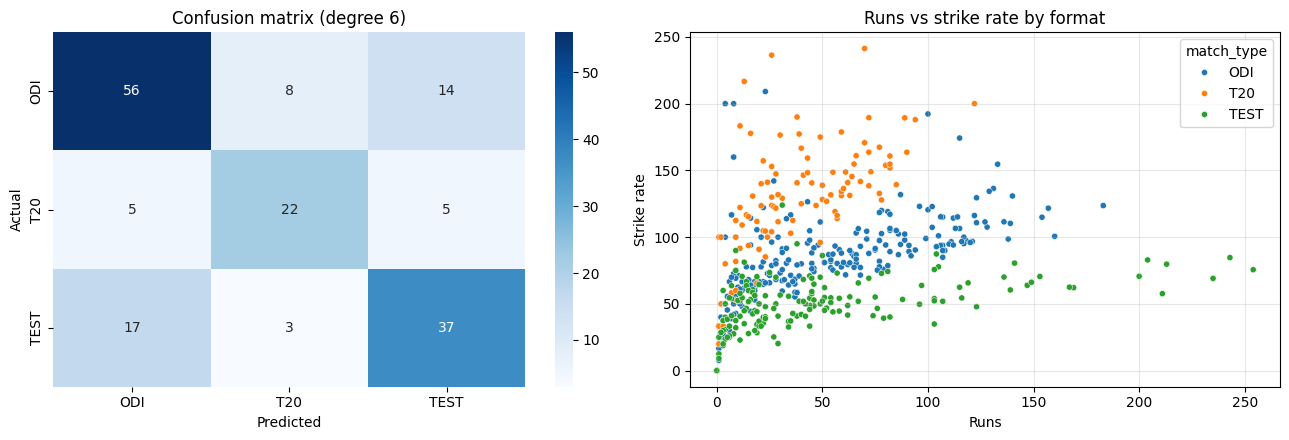

In [2]:
# Features are standardised first (polynomial kernels on raw runs and strike rates are numerically unstable and very slow).
# coef0=1 keeps the lower-order polynomial terms, which matter once the data is centred.
svc_model = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=6, coef0=1)).fit(x_train, y_train)
y_pred = svc_model.predict(x_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}, balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=svc_model.classes_, yticklabels=svc_model.classes_, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix (degree 6)")
sns.scatterplot(data=data_cricketer, x="Runs", y="SR", hue="match_type", ax=axes[1], s=20)
axes[1].set_ylabel("Strike rate"); axes[1].set_title("Runs vs strike rate by format"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/lab07_svm.png")
plt.show()

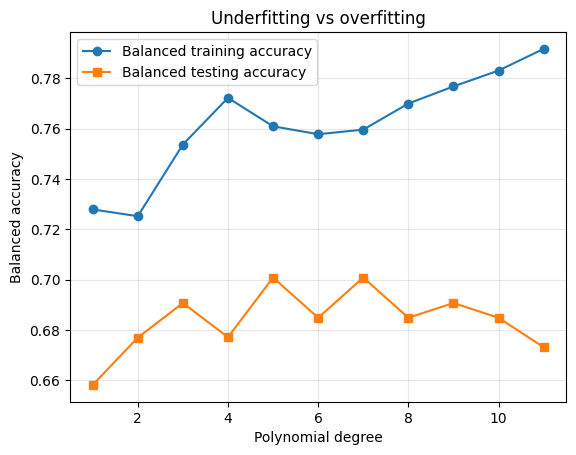

In [3]:
degree_range = range(1, 12)
train_acc, test_acc = [], []
for d in degree_range:
    model = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d, coef0=1)).fit(x_train, y_train)
    train_acc.append(balanced_accuracy_score(y_train, model.predict(x_train)))
    test_acc.append(balanced_accuracy_score(y_test, model.predict(x_test)))

plt.plot(degree_range, train_acc, "o-", label="Balanced training accuracy")
plt.plot(degree_range, test_acc, "s-", label="Balanced testing accuracy")
plt.xlabel("Polynomial degree"); plt.ylabel("Balanced accuracy")
plt.title("Underfitting vs overfitting"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

T20 innings stand out by their high strike rate, and Test innings by their low strike rate. ODI innings sit in between and overlap with both, which is where most errors happen.

## Report

1. **Support vectors** are the training points closest to the decision boundary; they alone define the margin. Points far from the boundary do not affect it, which makes SVM fairly robust to outliers.
2. **Hard vs soft margin:** a hard margin allows no misclassified training points and is sensitive to outliers. A soft margin (controlled by C) allows some violations in exchange for a wider margin and better generalisation.
3. **Non-linear boundaries:** kernels (polynomial, RBF) implicitly map the data to a higher-dimensional space where a linear separator exists.
4. **Gamma:** controls how far the influence of one training point reaches. A low gamma gives smooth boundaries (risk of underfitting); a high gamma gives very wiggly boundaries (risk of overfitting).
5. **Multi-class SVM:** one-vs-one trains a classifier for every pair of classes and takes a vote. One-vs-rest trains one classifier per class against all others and picks the most confident.